# Credit Default Model (Stacking & Ensembling)

ไฟล์นี้ถูกปรับแต่งใหม่ให้สามารถรันโมเดล **LightGBM** ควบคู่กับ **CatBoost** และรวมผลการทำนายเข้าด้วยกันผ่านเทคนิค **Ensembling** (Simple Blending, Weighted Average, และ Stacking)


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb

warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:          # รันนอก Jupyter
    display = print

# ---------- ไฟล์และชื่อรอบ ----------
DATA_DIR = Path(r"C:\Users\ice55\Downloads\Aihack Thailand 2026\data")   # <-- แก้ path ตรงนี้
RUN_NAME = "last_ensemble"              # ชื่อรอบ
TARGET   = "12-Month Default Flag"

# ---------- สวิตช์ ----------
USE_CATBOOST   = True        # เปิดใช้ CatBoost เพื่อทำ Ensembling (ต้อง pip install catboost)
USE_GENDER     = False       # ปิดไว้
USE_ID_FEATURE = False       # ปิดไว้

# ---------- Cross-validation ----------
SEED    = 42
N_FOLDS = 10

if USE_CATBOOST:
    from catboost import CatBoostClassifier

## 1. ข้อมูล
โหลดไฟล์ และตรวจสอบ

In [2]:
train    = pd.read_csv(DATA_DIR / "train_dataset.csv")
test     = pd.read_csv(DATA_DIR / "test_without_gt.csv")
template = pd.read_csv(DATA_DIR / "submission_template_for_test.csv")

assert train["ID"].is_unique and test["ID"].is_unique
assert set(template["ID"]) == set(test["ID"]), "ID ใน template ไม่ตรงกับ test"

print(f"train {train.shape} | test {test.shape} | template {template.shape}")
print(f"default rate (train) = {train[TARGET].mean():.4f}")

train (68546, 27) | test (137091, 26) | template (137091, 2)
default rate (train) = 0.0968


## 2. Features
สร้าง ratio และ frequency features

In [3]:
CAT_COLS = [
    "Application Channel", "Marital Status", "Occupation Category", "Industry Category",
    "Employment Type Category", "Insurance Type", "Business Entity Type",
    "Residence Type", "Residence Ownership Status",
]
if USE_GENDER:
    CAT_COLS.append("Gender")

PHONE_COLS = ["Home Phone Number Available", "Mobile Phone Number Available",
              "Employer Phone Number Available", "Driver Licence Number Available"]

def safe_div(a, b):
    b = b.astype(float)
    return a / b.where(b > 0)

def make_features(df):
    d = df.copy()
    income = d["Declared Annual Income"]
    debt   = d["Declared Borrowing Amount"]
    limit  = d["Desired Credit Limit"]
    n_dep  = d["Number of Dependents"]

    d["borrow_to_income"]   = safe_div(debt, income)
    d["limit_to_income"]    = safe_div(limit, income)
    d["exposure_to_income"] = safe_div(debt + limit, income)
    d["limit_to_borrow"]    = safe_div(limit, debt)
    d["avg_loan"]           = safe_div(debt, d["Declared Number of Borrowings"])
    d["rent_to_income"]       = safe_div(d["Rent Burden"], income)
    d["income_per_dependent"] = income / (n_dep + 1)
    d["children_share"]       = safe_div(d["Number of Dependent Children"], n_dep)
    d["residence_ratio"] = safe_div(d["Residence Period (in months)"], d["Age (in months)"])
    d["phone_count"]     = d[PHONE_COLS].sum(axis=1)
    return d

def add_freq_features(d):
    pairs = {
        "occ_x_ind":     ("Occupation Category", "Industry Category"),
        "size_x_entity": ("Company Size Category", "Business Entity Type"),
        "occ_x_emp":     ("Occupation Category", "Employment Type Category"),
    }
    for name, (a, b) in pairs.items():
        key = d[a].astype(str) + "_" + d[b].astype(str)
        d[name + "_freq"] = key.map(key.value_counts(normalize=True))
    return d

full = pd.concat([train.drop(columns=[TARGET]), test], ignore_index=True)
full = add_freq_features(make_features(full))
if USE_ID_FEATURE:
    full["id_prefix"] = full["ID"] // 10000
for c in CAT_COLS:
    full[c] = full[c].astype("category")

drop_cols    = ["ID"] + ([] if USE_GENDER else ["Gender"])
RAW_FEATURES = [c for c in train.columns if c not in drop_cols + [TARGET]]
ENG_FEATURES = [c for c in full.columns if c not in train.columns]
ALL_FEATURES = RAW_FEATURES + ENG_FEATURES

X_all  = full.iloc[:len(train)].reset_index(drop=True)
X_test = full.iloc[len(train):].reset_index(drop=True)
y      = train[TARGET].values

print(f"{len(RAW_FEATURES)} raw + {len(ENG_FEATURES)} engineered = {len(ALL_FEATURES)} features")

24 raw + 13 engineered = 37 features


## 3. โมเดลและ Cross-validation


In [4]:
folds      = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X_all, y))
scoreboard = []

def run_cv(fit_predict, features, name):
    oof, pred, fold_aucs = np.zeros(len(X_all)), np.zeros(len(X_test)), []
    for tr, va in folds:
        p_val, p_test = fit_predict(X_all.iloc[tr][features], y[tr],
                                    X_all.iloc[va][features], y[va],
                                    X_test[features])
        oof[va] = p_val
        pred   += p_test / len(folds)
        fold_aucs.append(roc_auc_score(y[va], p_val))

    row = dict(experiment=name, oof_auc=roc_auc_score(y, oof),
               fold_mean=np.mean(fold_aucs), fold_std=np.std(fold_aucs))
    scoreboard.append(row)
    print(f"{name:<28} OOF AUC {row['oof_auc']:.4f} | fold {row['fold_mean']:.4f} ± {row['fold_std']:.4f}")
    return oof, pred

# ---------- LightGBM ----------
LGB_PARAMS = dict(
    n_estimators=5000, 
    learning_rate=0.02,
    num_leaves=15,
    min_child_samples=200,
    subsample=0.8, 
    subsample_freq=1, 
    colsample_bytree=0.7,
    reg_lambda=10.0, 
    cat_smooth=50, 
    min_data_per_group=200,
    random_state=SEED, 
    n_jobs=-1, 
    verbose=-1,
)

lgb_fold_log = []

def fit_predict_lgb(X_tr, y_tr, X_va, y_va, X_te):
    model = lgb.LGBMClassifier(**LGB_PARAMS)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="auc",
              callbacks=[lgb.early_stopping(200, verbose=False)])
    lgb_fold_log.append(dict(cols=list(X_tr.columns),
                             gain=model.booster_.feature_importance(importance_type="gain"),
                             split=model.booster_.feature_importance(importance_type="split")))
    return model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]

# ---------- CatBoost ----------
def _cat_to_str(X):
    X = X.copy()
    for c in CAT_COLS:
        if c in X.columns:
            X[c] = X[c].astype(str)
    return X

def fit_predict_cat(X_tr, y_tr, X_va, y_va, X_te):
    cat_cols = [c for c in CAT_COLS if c in X_tr.columns]
    X_tr, X_va, X_te = _cat_to_str(X_tr), _cat_to_str(X_va), _cat_to_str(X_te)
    model = CatBoostClassifier(iterations=3000, learning_rate=0.03, depth=6, l2_leaf_reg=10,
                               eval_metric="AUC", random_seed=SEED, early_stopping_rounds=200,
                               cat_features=cat_cols, verbose=0, thread_count=-1)
    model.fit(X_tr, y_tr, eval_set=(X_va, y_va), use_best_model=True)
    return model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1]

## 4. ทดลอง


In [5]:
print("Training LGBM...")
oof_lgb, pred_lgb = run_cv(fit_predict_lgb, ALL_FEATURES, "LGBM: raw + engineered")
final_models = {"LGBM": (oof_lgb, pred_lgb)}

if USE_CATBOOST:
    print("Training CatBoost...")
    oof_cat, pred_cat = run_cv(fit_predict_cat, ALL_FEATURES, "CatBoost: raw + engineered")
    final_models["CatBoost"] = (oof_cat, pred_cat)

df_score = pd.DataFrame(scoreboard).set_index("experiment")
display(df_score.round(4))

Training LGBM...
LGBM: raw + engineered       OOF AUC 0.6521 | fold 0.6524 ± 0.0110
Training CatBoost...
CatBoost: raw + engineered   OOF AUC 0.6509 | fold 0.6514 ± 0.0099


,oof_auc,fold_mean,fold_std
experiment,,,
LGBM: raw + engineered,0.6521,0.6524,0.0110
CatBoost: raw + engineered,0.6509,0.6514,0.0099


## 5. รวมผล Ensembling Strategies
เลือกวิธีที่จะนำผลลัพธ์จาก Level-1 Model (LGBM, CatBoost) มารวมกัน

In [6]:
print("--- Ensembling Results ---")

# 1. Simple Blending (หาค่าเฉลี่ยปกติ)
oof_blend = np.mean([oof for oof, _ in final_models.values()], axis=0)
pred_blend = np.mean([pred for _, pred in final_models.values()], axis=0)
print(f"OOF AUC (Simple Blend): {roc_auc_score(y, oof_blend):.4f}")

# 2. Weighted Average
w_lgb, w_cat = 0.65, 0.35
if "CatBoost" in final_models:
    oof_weight = (final_models["LGBM"][0] * w_lgb) + (final_models["CatBoost"][0] * w_cat)
    pred_weight = (final_models["LGBM"][1] * w_lgb) + (final_models["CatBoost"][1] * w_cat)
else:
    oof_weight, pred_weight = final_models["LGBM"][0], final_models["LGBM"][1]
print(f"OOF AUC (Weighted {w_lgb}:{w_cat}): {roc_auc_score(y, oof_weight):.4f}")

# 3. Stacking ด้วย Logistic Regression
if "CatBoost" in final_models:
    X_meta_train = pd.DataFrame({"lgbm": final_models["LGBM"][0], "catboost": final_models["CatBoost"][0]})
    X_meta_test  = pd.DataFrame({"lgbm": final_models["LGBM"][1], "catboost": final_models["CatBoost"][1]})
    
    meta_model = LogisticRegression()
    oof_stacked = cross_val_predict(meta_model, X_meta_train, y, cv=folds, method='predict_proba')[:, 1]
    meta_model.fit(X_meta_train, y)
    pred_stacked = meta_model.predict_proba(X_meta_test)[:, 1]
    print(f"OOF AUC (Stacking): {roc_auc_score(y, oof_stacked):.4f}")
else:
    oof_stacked, pred_stacked = oof_blend, pred_blend

# >>> กำหนดค่าตัวแปรสุดท้ายสำหรับส่งประกวด <<< 
# (เลือกจาก oof_blend, oof_weight หรือ oof_stacked ตามที่ได้คะแนนสูงสุด)
oof_final = oof_stacked
pred_final = pred_stacked

--- Ensembling Results ---
OOF AUC (Simple Blend): 0.6537
OOF AUC (Weighted 0.65:0.35): 0.6537
OOF AUC (Stacking): 0.6537


## 6. เลือก Threshold จากโมเดลที่ Ensembling เสร็จแล้ว

OOF AUC (prob)  : 0.6537
OOF AUC (label) : 0.6131
threshold       : 0.0871


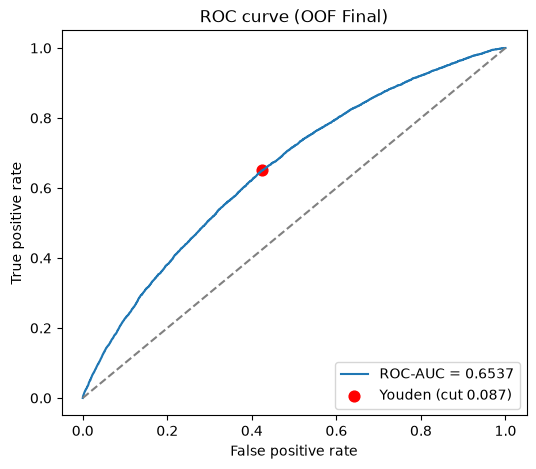

In [7]:
fpr, tpr, thresholds = roc_curve(y, oof_final)
best      = np.argmax(tpr - fpr)
threshold = thresholds[best]

print(f"OOF AUC (prob)  : {roc_auc_score(y, oof_final):.4f}")
print(f"OOF AUC (label) : {0.5 + (tpr[best] - fpr[best]) / 2:.4f}")
print(f"threshold       : {threshold:.4f}")

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y, oof_final):.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.scatter(fpr[best], tpr[best], s=60, color="red", label=f"Youden (cut {threshold:.3f})")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (OOF Final)")
plt.legend(loc="lower right")
plt.show()

## 7. Submit


In [8]:
def make_submission(values, path):
    sub = pd.DataFrame({"ID": test["ID"].values, TARGET: values})
    sub = template[["ID"]].merge(sub, on="ID", how="left")
    sub.to_csv(path, index=False)
    return sub

proba_file = f"submission_proba_{RUN_NAME}.csv"
label_file = f"submission_label_{RUN_NAME}.csv"
sub_proba  = make_submission(pred_final, proba_file)
sub_label  = make_submission((pred_final >= threshold).astype(int), label_file)

print(f"✅ บันทึกไฟล์เสร็จสิ้น")
print(f"Probability File: {proba_file}")
print(f"Label (0/1) File: {label_file}")

✅ บันทึกไฟล์เสร็จสิ้น
Probability File: submission_proba_last_ensemble.csv
Label (0/1) File: submission_label_last_ensemble.csv


## 8. Final Analysis: Youden's J, Confusion Matrix & Submission

ส่วนนี้ใช้ค่า Out-of-Fold (OOF) ที่ได้จาก Cross-Validation ของชุด Train (`oof_final`, `y`)
และค่าความน่าจะเป็นของชุด Test (`pred_final`) เพื่อ

1. หา **Optimal Threshold** ด้วย **Youden's J statistic** จาก ROC Curve
2. สร้าง **Confusion Matrix ของชุด Train** ด้วย Threshold ที่เลือก
3. สร้างไฟล์ **Submission** ทั้งแบบ probability และ label (0/1) ด้วย Threshold เดียวกัน
4. สรุปผลเชิงพฤติกรรมและข้อดี/ข้อเสียต่อธุรกิจ (Default Rate ประมาณ 9.67%)


1) OPTIMAL THRESHOLD (Youden's J) - TRAIN OOF
OOF ROC-AUC                    : 0.65366
OOF PR-AUC (Average Precision) : 0.16473
OOF Brier score                : 0.08530  (lower is better)
Best Youden's J                : 0.22614
Optimal threshold              : 0.087051
TPR (Recall) at threshold      : 0.65023
FPR at threshold               : 0.42410
Specificity at threshold       : 0.57590
Mean OOF probability           : 0.09685 | Actual default rate: 0.09677
PR-AUC lift vs prevalence      : 1.70x
Brier skill vs constant base   : 0.0240


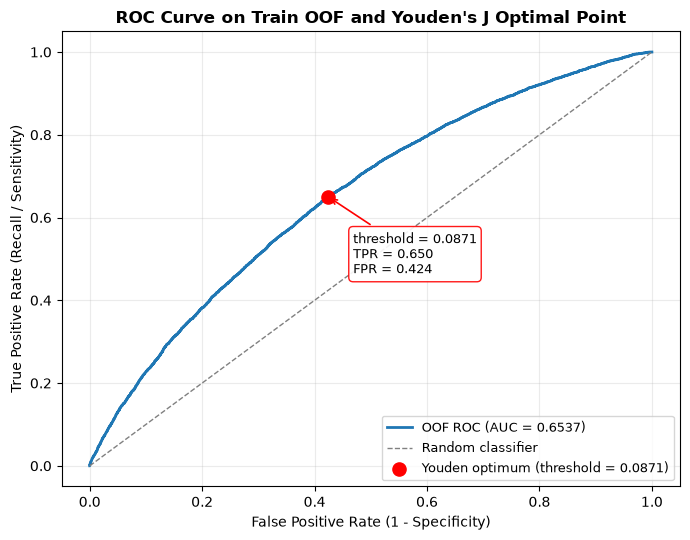

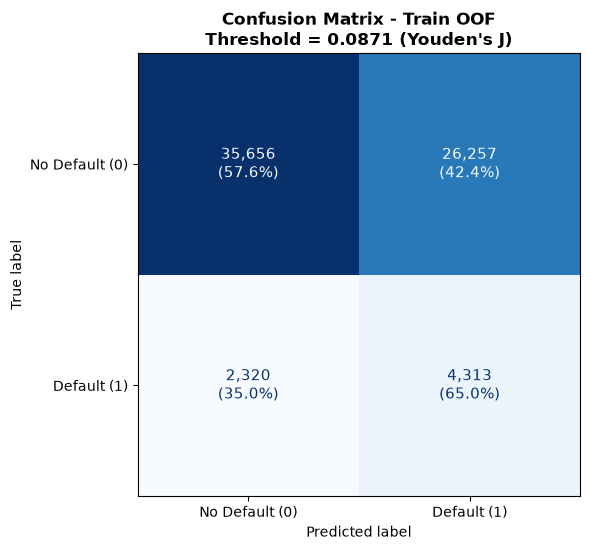


2) CONFUSION MATRIX & METRICS - TRAIN OOF
                              Pred 0      Pred 1       Total
Actual 0 (No Default)         35,656      26,257      61,913
Actual 1 (Default)             2,320       4,313       6,633
Total                         37,976      30,570      68,546

Recall / Sensitivity (TPR)       : 0.6502  (65.02%)
Precision (PPV)                  : 0.1411  (14.11%)
Specificity (TNR)                : 0.5759  (57.59%)
False Positive Rate (FPR)        : 0.4241  (42.41%)
False Negative Rate (FNR)        : 0.3498  (34.98%)
Negative Predictive Value (NPV)  : 0.9389  (93.89%)
Accuracy                          : 0.5831  (58.31%)
F1-score                          : 0.2319
Balanced Accuracy                 : 0.6131  (61.31%)
Flag rate (predicted default)     : 0.4460  (30,570 / 68,546)
Alerts per 1 true default         : 7.09
False positives per true positive : 6.09
Precision lift vs prevalence      : 1.46x

Threshold trade-off (Train OOF):
 threshold  flagged_rate  recal

In [9]:
# =========================================================
# 8. FINAL ANALYSIS: Youden's J / Confusion Matrix / Submission
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
)

# =========================================================
# 8.1 หา Threshold ที่ดีที่สุดด้วย Youden's J statistic
# =========================================================
fpr_final, tpr_final, thresholds_final = roc_curve(y, oof_final)
youden_j = tpr_final - fpr_final

best_idx = int(np.argmax(youden_j))

# หากมีหลาย threshold ที่ให้ Youden's J เท่ากัน ให้เลือกค่ากลาง ๆ
# เพื่อลดความอ่อนไหวต่อ tie มากเกินไป
tied_idx = np.flatnonzero(np.isclose(youden_j, youden_j[best_idx]))
if len(tied_idx) > 1:
    best_idx = int(tied_idx[len(tied_idx) // 2])

best_threshold = float(thresholds_final[best_idx])
if not np.isfinite(best_threshold):
    best_threshold = 1.0

auc_oof = roc_auc_score(y, oof_final)
ap_oof = average_precision_score(y, oof_final)
brier_oof = brier_score_loss(y, oof_final)
prevalence_for_lift = float(np.mean(y))
brier_baseline = prevalence_for_lift * (1 - prevalence_for_lift)
brier_skill = 1 - brier_oof / brier_baseline if brier_baseline > 0 else np.nan
pr_auc_lift = ap_oof / prevalence_for_lift if prevalence_for_lift > 0 else np.inf

print("=" * 82)
print("1) OPTIMAL THRESHOLD (Youden's J) - TRAIN OOF")
print("=" * 82)
print(f"OOF ROC-AUC                    : {auc_oof:.5f}")
print(f"OOF PR-AUC (Average Precision) : {ap_oof:.5f}")
print(f"OOF Brier score                : {brier_oof:.5f}  (lower is better)")
print(f"Best Youden's J                : {youden_j[best_idx]:.5f}")
print(f"Optimal threshold              : {best_threshold:.6f}")
print(f"TPR (Recall) at threshold      : {tpr_final[best_idx]:.5f}")
print(f"FPR at threshold               : {fpr_final[best_idx]:.5f}")
print(f"Specificity at threshold       : {1 - fpr_final[best_idx]:.5f}")
print(f"Mean OOF probability           : {oof_final.mean():.5f} | Actual default rate: {y.mean():.5f}")
print(f"PR-AUC lift vs prevalence      : {pr_auc_lift:.2f}x")
print(f"Brier skill vs constant base   : {brier_skill:.4f}")

# วาด ROC Curve และจุดที่ Youden's J ดีที่สุด
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fpr_final, tpr_final, lw=2, label=f"OOF ROC (AUC = {auc_oof:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="Random classifier")
ax.scatter(
    fpr_final[best_idx],
    tpr_final[best_idx],
    s=90,
    color="red",
    zorder=5,
    label=f"Youden optimum (threshold = {best_threshold:.4f})",
)
ax.annotate(
    f"threshold = {best_threshold:.4f}\nTPR = {tpr_final[best_idx]:.3f}\nFPR = {fpr_final[best_idx]:.3f}",
    xy=(fpr_final[best_idx], tpr_final[best_idx]),
    xytext=(18, -55),
    textcoords="offset points",
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="red", alpha=0.9),
    arrowprops=dict(arrowstyle="->", color="red", lw=1.2),
)
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Recall / Sensitivity)")
ax.set_title("ROC Curve on Train OOF and Youden's J Optimal Point", fontsize=12, fontweight="bold")
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# =========================================================
# 8.2 Confusion Matrix ของชุด Train ทั้งหมด (OOF)
# =========================================================
y_pred_train = (oof_final >= best_threshold).astype(int)
cm = confusion_matrix(y, y_pred_train, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6.6, 5.6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default (0)", "Default (1)"],
)
disp.plot(cmap="Blues", ax=ax, values_format="d", colorbar=False)

# เพิ่มเปอร์เซ็นต์แบบ row-normalized ใต้ตัวเลขในแต่ละช่อง
# (ยังใช้ ConfusionMatrixDisplay ในการวาดตามที่ต้องการ)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        text_idx = i * cm.shape[1] + j
        if text_idx < len(ax.texts):
            count = cm[i, j]
            row_total = cm[i].sum()
            row_pct = (count / row_total * 100) if row_total else 0.0
            ax.texts[text_idx].set_text(f"{count:,}\n({row_pct:.1f}%)")
            ax.texts[text_idx].set_fontsize(11)

ax.set_title(
    f"Confusion Matrix - Train OOF\nThreshold = {best_threshold:.4f} (Youden's J)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# =========================================================
# 8.3 คำนวณ Metrics และตารางเทียบ Threshold
# =========================================================
n_total = int(len(y))
n_pos = int((y == 1).sum())
n_neg = int((y == 0).sum())
prevalence = n_pos / n_total
flagged = int(y_pred_train.sum())
flag_rate = flagged / n_total

recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
fpr_value = fp / (fp + tn) if (fp + tn) > 0 else 0.0
fnr_value = fn / (fn + tp) if (fn + tp) > 0 else 0.0
npv = tn / (tn + fn) if (tn + fn) > 0 else 0.0
accuracy = accuracy_score(y, y_pred_train)
f1 = f1_score(y, y_pred_train, zero_division=0)
balanced_acc = balanced_accuracy_score(y, y_pred_train)
alerts_per_tp = (tp + fp) / tp if tp > 0 else np.inf
fp_per_tp = fp / tp if tp > 0 else np.inf
implied_cost_ratio = (1 - best_threshold) / best_threshold if best_threshold > 0 else np.inf

print()
print("=" * 82)
print("2) CONFUSION MATRIX & METRICS - TRAIN OOF")
print("=" * 82)
print(f"{'':<24}{'Pred 0':>12}{'Pred 1':>12}{'Total':>12}")
print(f"{'Actual 0 (No Default)':<24}{tn:>12,}{fp:>12,}{tn + fp:>12,}")
print(f"{'Actual 1 (Default)':<24}{fn:>12,}{tp:>12,}{fn + tp:>12,}")
print(f"{'Total':<24}{tn + fn:>12,}{fp + tp:>12,}{n_total:>12,}")
print()
print(f"Recall / Sensitivity (TPR)       : {recall:.4f}  ({recall:.2%})")
print(f"Precision (PPV)                  : {precision:.4f}  ({precision:.2%})")
print(f"Specificity (TNR)                : {specificity:.4f}  ({specificity:.2%})")
print(f"False Positive Rate (FPR)        : {fpr_value:.4f}  ({fpr_value:.2%})")
print(f"False Negative Rate (FNR)        : {fnr_value:.4f}  ({fnr_value:.2%})")
print(f"Negative Predictive Value (NPV)  : {npv:.4f}  ({npv:.2%})")
print(f"Accuracy                          : {accuracy:.4f}  ({accuracy:.2%})")
print(f"F1-score                          : {f1:.4f}")
print(f"Balanced Accuracy                 : {balanced_acc:.4f}  ({balanced_acc:.2%})")
print(f"Flag rate (predicted default)     : {flag_rate:.4f}  ({flagged:,} / {n_total:,})")
print(f"Alerts per 1 true default         : {alerts_per_tp:.2f}")
print(f"False positives per true positive : {fp_per_tp:.2f}")
print(f"Precision lift vs prevalence      : {precision / prevalence:.2f}x")

# ตารางเทียบ threshold เพื่อดู trade-off ก่อนนำไปใช้ทางธุรกิจ
compare_thresholds = sorted(set([
    0.05,
    0.075,
    best_threshold,
    0.10,
    0.15,
    0.20,
    0.30,
    0.50,
]))
comparison_rows = []
for thr in compare_thresholds:
    pred_thr = (oof_final >= thr).astype(int)
    cm_thr = confusion_matrix(y, pred_thr, labels=[0, 1])
    tn_thr, fp_thr, fn_thr, tp_thr = cm_thr.ravel()
    comparison_rows.append({
        "threshold": thr,
        "flagged_rate": pred_thr.mean(),
        "recall": tp_thr / (tp_thr + fn_thr) if (tp_thr + fn_thr) else 0.0,
        "precision": tp_thr / (tp_thr + fp_thr) if (tp_thr + fp_thr) else 0.0,
        "specificity": tn_thr / (tn_thr + fp_thr) if (tn_thr + fp_thr) else 0.0,
        "F1": f1_score(y, pred_thr, zero_division=0),
        "FP": int(fp_thr),
        "FN": int(fn_thr),
    })

comparison_df = pd.DataFrame(comparison_rows)
print()
print("Threshold trade-off (Train OOF):")
print(comparison_df.round(4).to_string(index=False))

# =========================================================
# 8.4 สร้างไฟล์ Submission สำหรับ Test Data
# =========================================================
SUBMIT_RUN_NAME = f"{RUN_NAME}_youden"
proba_file = f"submission_proba_{SUBMIT_RUN_NAME}.csv"
label_file = f"submission_label_{SUBMIT_RUN_NAME}.csv"


def make_submission_final(values, path):
    sub = pd.DataFrame({"ID": test["ID"].values, TARGET: values})
    sub = template[["ID"]].merge(sub, on="ID", how="left")
    sub.to_csv(path, index=False)
    return sub


assert len(pred_final) == len(test), "pred_final กับ test มีจำนวนแถวไม่ตรงกัน"
assert not np.isnan(pred_final).any(), "pred_final มีค่า NaN"

test_pred_class = (pred_final >= best_threshold).astype(int)
sub_proba = make_submission_final(pred_final, proba_file)
sub_label = make_submission_final(test_pred_class, label_file)

print()
print("=" * 82)
print("3) SUBMISSION FILES")
print("=" * 82)
print(f"Threshold ที่ใช้                   : {best_threshold:.6f}")
print(f"Test rows                          : {len(sub_label):,}")
print(f"Predicted Default (label = 1)      : {int(test_pred_class.sum()):,} ({test_pred_class.mean():.2%})")
print(f"Mean predicted probability (test)  : {pred_final.mean():.6f}")
print(f"Min / Max probability (test)       : {pred_final.min():.6f} / {pred_final.max():.6f}")
print(f"Probability file                   : {proba_file}")
print(f"Label file                         : {label_file}")

# ตรวจสอบว่า submission ครบทุก ID และไม่มี missing
assert len(sub_proba) == len(template), "จำนวนแถว submission ไม่ตรงกับ template"
assert sub_proba["ID"].is_unique and sub_label["ID"].is_unique
assert sub_proba[["ID", TARGET]].notna().all().all()
assert sub_label[TARGET].isin([0, 1]).all()

# =========================================================
# 8.5 สรุปผลเชิงพฤติกรรม (Dynamic Summary)
# =========================================================
print()
print("=" * 82)
print("4) BEHAVIORAL / BUSINESS SUMMARY")
print("=" * 82)
print(f"ข้อมูล Train: {n_total:,} ราย | Default จริง {n_pos:,} ราย ({prevalence:.2%}) | ไม่ Default {n_neg:,} ราย")
print(f"โมเดลเตือน (pred = 1): {flagged:,} ราย ({flag_rate:.2%} ของ Train)")
print()
print(f"- จับ Default ได้ (TP)                 : {tp:,} / {n_pos:,} = Recall {recall:.2%}")
print(f"- พลาด Default (FN)                   : {fn:,} ราย = Miss rate {fnr_value:.2%}")
print(f"- เตือนผิดว่าเป็น Default (FP)        : {fp:,} ราย")
print(f"- ไม่เตือนและถูก (TN)                 : {tn:,} ราย")
print(f"- ในกลุ่มที่โมเดลเตือน เป็น Default จริง (Precision) : {precision:.2%}")
print(f"- False Positive คิดเป็น               : {fp / n_neg:.2%} ของคนไม่ Default ทั้งหมด")
print(f"- False Positive คิดเป็น               : {fp / flagged:.2%} ของจำนวนที่เตือนทั้งหมด")
print(f"- ต้องเตือนประมาณ {alerts_per_tp:.2f} ครั้ง เพื่อจับ Default ได้ 1 ราย")
print(f"- Accuracy {accuracy:.2%} เทียบ baseline all-negative {1 - prevalence:.2%}")
print()
print("ข้อควรระวังทางธุรกิจ:")
print(f"- Youden's J maximize TPR - FPR จึงให้น้ำหนัก Recall/Sensitivity กับ Specificity")
print("  ใกล้เคียงกัน แต่ไม่ได้แปลว่า profit สูงสุด เพราะต้นทุน FN กับ FP ไม่เท่ากัน")
print(f"- ถ้า probability มี calibration ดี threshold {best_threshold:.4f} จะ implicitly สอดคล้องกับ")
print(f"  ต้นทุน FN:FP ประมาณ {implied_cost_ratio:.1f}:1 (FN แพงกว่า FP ประมาณ {implied_cost_ratio:.1f} เท่า)")
print("  แต่ถ้า probability ไม่ calibrated ควรใช้ threshold นี้เป็น ranking cutoff มากกว่า")
print("  การตีความเป็น probability ของการ default จริง")
print("- ที่ Default Rate ต่ำ (~9.67%) precision จะถูกจำกัดด้วย base rate;")
print("  ควรดู Recall, PR-AUC, จำนวน FP และต้นทุนต่อธุรกิจร่วมกัน ไม่ควรดู Accuracy อย่างเดียว")


### สรุปผลเชิงพฤติกรรมจากผลรันจริง

> กำลังรอผลการรันเพื่อเติมตัวเลขจริง
